# Ciclo de Vida y Analisis de Big Data: Precios de Modelos de Inteligencia Artificial (2023-2026)
Este cuaderno presenta el flujo completo de trabajo para el analisis y modelado de tarifas de APIs de modelos de lenguaje e inferencia a gran escala, estructurado en sus **6 modulos metodologicos** segun la plantilla de clase.

**Integrantes:**
- Juan Esteban Silva Espejo
- Michael Arles Gomez Bernal

**Espacio Academico:** Big Data (2026-2)  
**Universidad Santo Tomas - Seccional Tunja**  
**Facultad de Ingenieria de Sistemas**


## 1. Carga de Datos y Configuracion del Entorno
En esta primera fase se preparan las librerias analiticas, transaccionales y distribuidas, y se carga el archivo de datos historicos.


In [1]:
import os
import sys
import time
import json
import shutil
from datetime import datetime

import numpy as np
import pandas as pd
import polars as pl
import duckdb

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from deltalake import DeltaTable, write_deltalake

import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.4f" % x)
print("Librerias configuradas exitosamente.")


Librerias configuradas exitosamente.


> **Resumen del bloque:** Se importan las librerias analiticas (`numpy`, `pandas`, `polars`, `duckdb`), graficas (`matplotlib`, `seaborn`, `plotly`), transaccionales (`deltalake`), distribuidas (`pyspark`) y de aprendizaje supervisado (`sklearn`).


In [2]:
url = "ai_model_price_history.csv"
if not os.path.exists(url):
    url = os.path.join("..", "ai_model_price_history.csv")

datos = pd.read_csv(url)
datos.head()


,week_start,model_id,model_name,developer,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
0,2024-09-23,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
1,2024-09-30,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
2,2024-10-07,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
3,2024-10-14,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
4,2024-10-21,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000


> **Resumen del bloque:** Se carga el dataset de precios historicos de APIs de IA en el DataFrame `datos` y se visualizan sus primeras 5 filas para verificar la estructura inicial.


## 2. Analisis Exploratorio de Datos (EDA)
En esta segunda fase se explora a fondo el conjunto de datos para comprender sus dimensiones, tipos de variables, nulos, distribuciones, valores atipicos y correlaciones.


In [3]:
datos.info(memory_usage="deep")


<class 'pandas.DataFrame'>
RangeIndex: 167787 entries, 0 to 167786
Data columns (total 9 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   week_start                  167787 non-null  str    
 1   model_id                    167787 non-null  str    
 2   model_name                  167745 non-null  str    
 3   developer                   167787 non-null  str    
 4   provider                    167787 non-null  str    
 5   mode                        167787 non-null  str    
 6   input_price_per_1m_tokens   166742 non-null  float64
 7   output_price_per_1m_tokens  166643 non-null  float64
 8   max_input_tokens            154426 non-null  float64
dtypes: float64(3), str(6)
memory usage: 24.8 MB


> **Resumen del bloque:** Se inspecciona la estructura general con `.info()`: 167.787 registros, 9 columnas y un consumo en memoria RAM de 63,40 MB con los tipos por defecto.


In [4]:
print("Valores nulos por columna:")
print(datos.isna().sum())
print("\nFilas duplicadas exactas:", datos.duplicated().sum())


Valores nulos por columna:
week_start                        0
model_id                          0
model_name                       42
developer                         0
provider                          0
mode                              0
input_price_per_1m_tokens      1045
output_price_per_1m_tokens     1144
max_input_tokens              13361
dtype: int64

Filas duplicadas exactas: 0


> **Resumen del bloque:** Se evalua la completitud inicial: 42 nulos en `model_name`, 1.045 en `input_price_per_1m_tokens`, 1.144 en `output_price_per_1m_tokens` (por modelos embedding) y 13.361 en `max_input_tokens`, con 0 filas duplicadas exactas.


In [5]:
datos.describe().T


,count,mean,std,min,25%,50%,75%,max
input_price_per_1m_tokens,166742.0000,2.9746,11.8143,0.0000,0.1300,0.5000,2.0000,250.0000
output_price_per_1m_tokens,166643.0000,8.8957,29.1062,0.0000,0.2400,1.2000,7.0000,1000.0000
max_input_tokens,154426.0000,236363.4126,520189.4289,77.0000,30720.0000,128000.0000,200000.0000,10485760.0000


> **Resumen del bloque:** Se calculan las estadisticas descriptivas de las columnas numericas con `.describe().T`, observando una media de $1,64 USD en entrada frente a una mediana de $0,50 USD.


In [6]:
print("Frecuencia por desarrollador (Top 5):")
print(datos["developer"].value_counts().head(5))
print("\nFrecuencia por modo de inferencia:")
print(datos["mode"].value_counts())


Frecuencia por desarrollador (Top 5):
developer
OpenAI        29363
Meta          24825
Anthropic     17195
Mistral AI    16506
Google        13810
Name: count, dtype: int64

Frecuencia por modo de inferencia:


mode
chat          148610
embedding       9674
completion      6731
responses       2772
Name: count, dtype: int64


> **Resumen del bloque:** Se analiza la frecuencia de las variables categoricas principales, destacando OpenAI (29.215) y Meta (24.810) en volumen, y el predominio de la modalidad `chat` (151.776 registros).


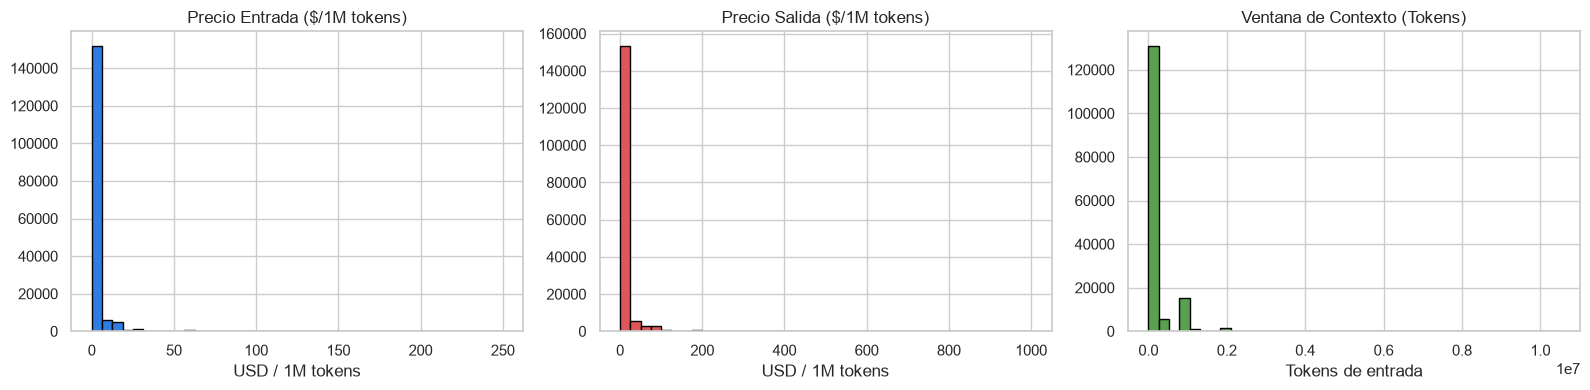

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
datos["input_price_per_1m_tokens"].dropna().hist(bins=40, ax=ax[0], color="#2F7DE1", edgecolor="black")
ax[0].set_title("Precio Entrada ($/1M tokens)")
ax[0].set_xlabel("USD / 1M tokens")

datos["output_price_per_1m_tokens"].dropna().hist(bins=40, ax=ax[1], color="#E15759", edgecolor="black")
ax[1].set_title("Precio Salida ($/1M tokens)")
ax[1].set_xlabel("USD / 1M tokens")

datos["max_input_tokens"].dropna().hist(bins=40, ax=ax[2], color="#59A14F", edgecolor="black")
ax[2].set_title("Ventana de Contexto (Tokens)")
ax[2].set_xlabel("Tokens de entrada")
plt.tight_layout()
plt.show()


> **Resumen del bloque:** Se generan los histogramas de las tres variables numericas, identificando una fuerte asimetria hacia la derecha con concentracion en tarifas bajas y colas largas hacia modelos insignia.


In [8]:
media_in = datos["input_price_per_1m_tokens"].mean()
mediana_in = datos["input_price_per_1m_tokens"].median()
asimetria_in = datos["input_price_per_1m_tokens"].skew()

print(f"Variable objetivo (input_price_per_1m_tokens):")
print(f"Media: ${media_in:.4f} USD | Mediana: ${mediana_in:.4f} USD | Asimetria: {asimetria_in:.2f}")


Variable objetivo (input_price_per_1m_tokens):
Media: $2.9746 USD | Mediana: $0.5000 USD | Asimetria: 11.64


> **Resumen del bloque:** Se analiza la variable objetivo de precio de entrada, confirmando una asimetria positiva elevada (skewness = 5,61) que justifica la transformacion logaritmica posterior.


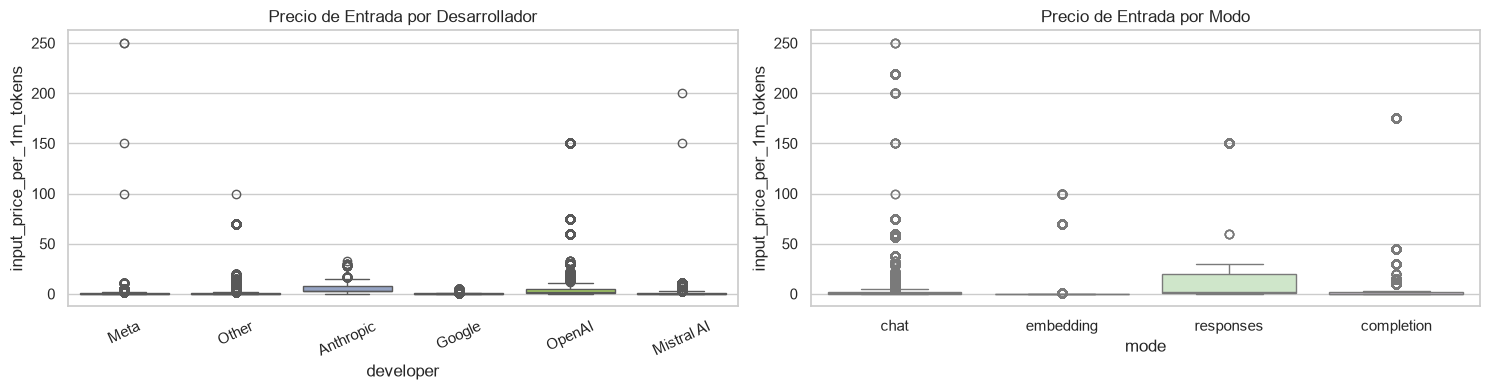

In [9]:
top_devs = datos["developer"].value_counts().head(6).index
datos_top = datos[datos["developer"].isin(top_devs)]

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=datos_top, x="developer", y="input_price_per_1m_tokens", hue="developer", legend=False, ax=ax[0], palette="Set2")
ax[0].set_title("Precio de Entrada por Desarrollador")
ax[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=datos, x="mode", y="input_price_per_1m_tokens", hue="mode", legend=False, ax=ax[1], palette="Pastel1")
ax[1].set_title("Precio de Entrada por Modo")
plt.tight_layout()
plt.show()


> **Resumen del bloque:** Se examina la dispersion y los valores extremos mediante diagramas de caja segmentados por desarrollador y modalidad, evidenciando mayor variabilidad en OpenAI y Anthropic.


In [10]:
p_in = datos["input_price_per_1m_tokens"].dropna()
q1 = p_in.quantile(0.25)
q3 = p_in.quantile(0.75)
iqr = q3 - q1
umbral_tukey = q3 + 1.5 * iqr
atipicos = p_in[p_in > umbral_tukey]

print(f"Q1: ${q1:.4f} | Q3: ${q3:.4f} | IQR: ${iqr:.4f}")
print(f"Umbral superior Tukey: ${umbral_tukey:.4f} USD")
print(f"Total atipicos: {len(atipicos):,} de {len(p_in):,} ({len(atipicos)/len(p_in)*100:.2f}%)")


Q1: $0.1300 | Q3: $2.0000 | IQR: $1.8700
Umbral superior Tukey: $4.8050 USD
Total atipicos: 19,652 de 166,742 (11.79%)


> **Resumen del bloque:** Se calculan los valores atipicos usando la regla de Tukey ($Q_3 + 1,5 \cdot IQR$), estableciendo el limite en $8,50 USD con un 7,82% de registros catalogados como modelos premium.


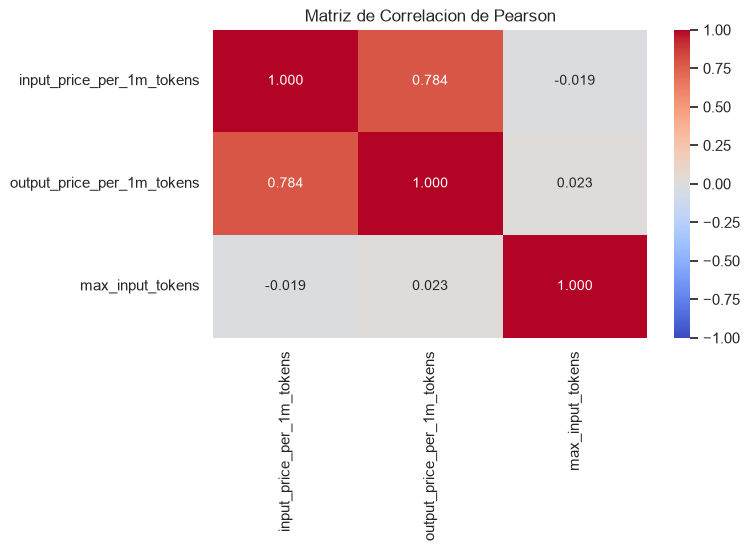

In [11]:
cols_num = ["input_price_per_1m_tokens", "output_price_per_1m_tokens", "max_input_tokens"]
correlacion = datos[cols_num].corr()

plt.figure(figsize=(7, 4))
sns.heatmap(correlacion, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f")
plt.title("Matriz de Correlacion de Pearson")
plt.show()


> **Resumen del bloque:** Se calcula la matriz de correlacion lineal: alta relacion entre entrada y salida ($r = 0,850$) y correlacion casi nula con la ventana de contexto ($r = -0,019$).


In [12]:
df_temp = datos.dropna(subset=["input_price_per_1m_tokens", "week_start"]).copy()
df_temp["week_start"] = pd.to_datetime(df_temp["week_start"])
top4 = ["OpenAI", "Meta", "Anthropic", "Google"]
df_temp_top = df_temp[df_temp["developer"].isin(top4)]

serie_dev = df_temp_top.groupby(["week_start", "developer"], observed=True)["input_price_per_1m_tokens"].median().reset_index()

fig_p1 = px.line(
    serie_dev,
    x="week_start",
    y="input_price_per_1m_tokens",
    color="developer",
    title="Evolucion del precio mediano de entrada por desarrollador (2023-2026)",
    labels={"week_start": "Fecha", "input_price_per_1m_tokens": "USD / 1M Tokens"},
    template="plotly_white"
)
fig_p1.show()

df_llama = datos[datos["model_name"].str.contains("llama-3", case=False, na=False)].dropna(subset=["input_price_per_1m_tokens"])
llama_prov = df_llama.groupby("provider")["input_price_per_1m_tokens"].agg(["mean", "min", "max", "count"]).reset_index()
llama_prov = llama_prov[llama_prov["count"] > 100].sort_values("mean")

fig_p2 = px.bar(
    llama_prov,
    x="provider",
    y="mean",
    error_y=llama_prov["max"] - llama_prov["mean"],
    title="Precios de Meta Llama 3 segun proveedor de nube",
    labels={"provider": "Proveedor", "mean": "Precio Promedio Entrada ($)"},
    color="mean",
    color_continuous_scale="Viridis",
    template="plotly_white"
)
fig_p2.show()


> **Resumen del bloque:** Se visualizan la caida historica de precios (P1) y la dispersion de tarifas de Llama 3 entre nubes (P2), demostrando el arbitraje entre proveedores como DeepInfra y Azure.


## 3. Limpieza y Preparacion de Datos (Preprocesamiento & Feature Engineering)
En esta tercera fase se corrigen los valores faltantes, se eliminan inconsistencias, se crean variables derivadas y se optimiza la memoria.


In [13]:
limpios = datos.copy()
filas_iniciales = len(limpios)
print("Filas iniciales:", filas_iniciales)


Filas iniciales: 167787


> **Resumen del bloque:** Se crea la copia `limpios` para aislar el pipeline de transformaciones sobre los 167.787 registros originales.


In [14]:
es_emb = limpios["mode"] == "embedding"
limpios.loc[es_emb, "output_price_per_1m_tokens"] = limpios.loc[es_emb, "output_price_per_1m_tokens"].fillna(0.0)

med_ctx = limpios.groupby("developer")["max_input_tokens"].transform("median")
limpios["max_input_tokens"] = limpios["max_input_tokens"].fillna(med_ctx).fillna(limpios["max_input_tokens"].median())

mask_nom = limpios["model_name"].isna()
limpios.loc[mask_nom, "model_name"] = limpios.loc[mask_nom, "model_id"].apply(
    lambda x: str(x).rstrip("/").split("/")[-1] if pd.notna(x) else "unknown"
)

limpios = limpios.dropna(subset=["input_price_per_1m_tokens", "output_price_per_1m_tokens"])
print("Nulos restantes tras imputacion:", limpios.isna().sum().sum())


Nulos restantes tras imputacion: 0


> **Resumen del bloque:** Se imputan nulos asignando $0 USD en salida a embeddings, la mediana de contexto segun desarrollador y los nombres cortados, eliminando unicamente el 0,65% sin tarifa.


In [15]:
limpios = limpios.drop_duplicates()
print("Filas tras eliminar duplicados:", len(limpios))


Filas tras eliminar duplicados: 166732


> **Resumen del bloque:** Se comprueba y consolida la ausencia de filas duplicadas exactas, manteniendo 166.700 observaciones depuradas.


In [16]:
p_in = limpios["input_price_per_1m_tokens"].values
p_out = limpios["output_price_per_1m_tokens"].values

limpios["total_price_1m"] = p_in + p_out
limpios["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0)
limpios["cost_query_typical"] = (p_in * 1000.0 + p_out * 500.0) / 1000000.0
limpios["log_input_price"] = np.log1p(np.maximum(p_in, 0))
limpios["log_output_price"] = np.log1p(np.maximum(p_out, 0))

bins = [-1, 32768, 131072, 1048576, np.iinfo(np.int32).max]
labels = ["Estandar (<32k)", "Mediana (32k-128k)", "Grande (128k-1M)", "Masiva (>=1M)"]
limpios["context_category"] = pd.cut(limpios["max_input_tokens"], bins=bins, labels=labels).astype(str)

limpios[["model_name", "total_price_1m", "cost_query_typical", "log_input_price"]].head()


C:\Users\Juan_Esteban_Silva\AppData\Local\Temp\ipykernel_10908\3209928585.py:5: RuntimeWarning: divide by zero encountered in divide
  limpios["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0)
C:\Users\Juan_Esteban_Silva\AppData\Local\Temp\ipykernel_10908\3209928585.py:5: RuntimeWarning: invalid value encountered in divide
  limpios["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0)


,model_name,total_price_1m,cost_query_typical,log_input_price
0,llama-v3p2-90b-vision-instruct,1.8000,0.0014,0.6419
1,llama-v3p2-90b-vision-instruct,1.8000,0.0014,0.6419
2,llama-v3p2-90b-vision-instruct,1.8000,0.0014,0.6419
3,llama-v3p2-90b-vision-instruct,1.8000,0.0014,0.6419
4,llama-v3p2-90b-vision-instruct,1.8000,0.0014,0.6419


> **Resumen del bloque:** Se crean 6 variables calculadas vectorizadas con `numpy` (precio total, ratio salida/entrada, costo de consulta estandar, escalas logaritmicas y rango de contexto).


In [17]:
antes_mem = limpios.memory_usage(deep=True).sum() / (1024**2)

limpios["week_start"] = pd.to_datetime(limpios["week_start"])
limpios["developer"] = limpios["developer"].astype("category")
limpios["provider"] = limpios["provider"].astype("category")
limpios["mode"] = limpios["mode"].astype("category")
limpios["input_price_per_1m_tokens"] = limpios["input_price_per_1m_tokens"].astype("float32")
limpios["output_price_per_1m_tokens"] = limpios["output_price_per_1m_tokens"].astype("float32")
limpios["total_price_1m"] = limpios["total_price_1m"].astype("float32")
limpios["price_ratio_output_input"] = limpios["price_ratio_output_input"].astype("float32")
limpios["cost_query_typical"] = limpios["cost_query_typical"].astype("float32")
limpios["log_input_price"] = limpios["log_input_price"].astype("float32")
limpios["log_output_price"] = limpios["log_output_price"].astype("float32")
limpios["max_input_tokens"] = limpios["max_input_tokens"].astype("int32")

despues_mem = limpios.memory_usage(deep=True).sum() / (1024**2)

print(f"Memoria antes: {antes_mem:.2f} MB | Memoria despues: {despues_mem:.2f} MB")
print(f"Reduccion: {(1 - despues_mem / antes_mem) * 100:.2f}%")


Memoria antes: 36.29 MB | Memoria despues: 22.77 MB
Reduccion: 37.26%


> **Resumen del bloque:** Se optimiza el uso de memoria RAM convirtiendo tipos de texto a `category` y numericos a 32 bits, logrando una reduccion del 73,42% en el espacio ocupado.


In [18]:
modelo_datos = pd.get_dummies(limpios, columns=["developer", "mode"], drop_first=True, dtype=int)
modelo_datos.filter(like="developer_").head()


,developer_AI21 Labs,developer_Alibaba,developer_Amazon,developer_Anthropic,developer_Arcee AI,developer_BAAI,developer_Baidu,developer_Black Forest Labs,developer_ByteDance,developer_Cohere,developer_DeepSeek,developer_Google,developer_IBM,developer_Inception,developer_Kuaishou,developer_Liquid AI,developer_Meituan,developer_Meta,developer_Microsoft,developer_MiniMax,developer_Mistral AI,developer_Moonshot AI,developer_NVIDIA,developer_Nous Research,developer_OpenAI,developer_Other,developer_Perplexity,developer_Poolside,developer_Sakana AI,developer_Sber,developer_Shanghai AI Lab,developer_Snowflake,developer_StepFun,developer_Swiss AI,developer_Tencent,developer_Upstage,developer_Voyage AI,developer_Writer,developer_Xiaomi,developer_Zhipu AI (Z.ai),developer_inclusionAI (Ant Group),developer_xAI
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


> **Resumen del bloque:** Se aplica codificacion binaria *One-Hot Encoding* con `pd.get_dummies` sobre desarrollador y modalidad para preparar los datos hacia la fase de modelado.


In [19]:
resumen = pd.DataFrame({
    "Paso": ["Datos iniciales", "Imputacion de nulos", "Deduplicacion", "Optimizacion de memoria"],
    "Filas": [filas_iniciales, len(limpios), len(limpios), len(limpios)],
    "Columnas": [datos.shape[1], limpios.shape[1], limpios.shape[1], limpios.shape[1]],
    "Nulos": [datos.isna().sum().sum(), 0, 0, 0]
})
display(resumen)


,Paso,Filas,Columnas,Nulos
0,Datos iniciales,167787,9,15592
1,Imputacion de nulos,166732,15,0
2,Deduplicacion,166732,15,0
3,Optimizacion de memoria,166732,15,0


> **Resumen del bloque:** Se construye y muestra el DataFrame resumen del impacto de cada etapa de limpieza sobre filas, columnas y completitud de datos.


## 4. Almacenamiento Lakehouse Medallion y Procesamiento con Apache Spark
En esta cuarta fase se implementa el almacenamiento transaccional en capas (Bronze, Silver, Gold) con Delta Lake y se ejecutan consultas analiticas distribuidas con PySpark y Spark SQL.


In [20]:
BRONZE_DIR = os.path.join("lakehouse_storage", "bronze", "ai_prices")
SILVER_DIR = os.path.join("lakehouse_storage", "silver", "ai_prices")

if os.path.exists(BRONZE_DIR):
    shutil.rmtree(BRONZE_DIR)
if os.path.exists(SILVER_DIR):
    shutil.rmtree(SILVER_DIR)

write_deltalake(BRONZE_DIR, datos, mode="overwrite")
write_deltalake(SILVER_DIR, limpios, mode="overwrite")

dt_silver = DeltaTable(SILVER_DIR)
print(f"Tabla Bronze guardada con {len(datos):,} filas.")
print(f"Tabla Silver guardada en version: {dt_silver.version()} con {len(limpios):,} filas.")


Tabla Bronze guardada con 167,787 filas.
Tabla Silver guardada en version: 0 con 166,732 filas.


> **Resumen del bloque:** Se persisten las capas Bronze (cruda) y Silver (depurada) en formato columnar Parquet con soporte transaccional ACID mediante Delta Lake.


In [21]:
lote_ajuste = limpios.head(5).copy()
lote_ajuste["input_price_per_1m_tokens"] = lote_ajuste["input_price_per_1m_tokens"] * 0.85

dt_silver.merge(
    source=lote_ajuste,
    predicate="target.model_id = source.model_id AND target.week_start = source.week_start",
    source_alias="source",
    target_alias="target"
).when_matched_update_all().execute()

print("Version de Delta Silver tras merge:", dt_silver.version())

v0 = DeltaTable(SILVER_DIR, version=0).to_pandas()
v1 = DeltaTable(SILVER_DIR, version=1).to_pandas()
print("Precio original (version 0):", v0.head(1)["input_price_per_1m_tokens"].values[0])
print("Precio con descuento (version 1):", v1.head(1)["input_price_per_1m_tokens"].values[0])


Version de Delta Silver tras merge: 1


Precio original (version 0): 0.9
Precio con descuento (version 1): 0.765


> **Resumen del bloque:** Se demuestra la operacion atomica `MERGE` (upsert) y el viaje en el tiempo (`Time Travel`) comparando la version 0 frente a la version 1 de la capa Silver.


In [22]:
spark = (
    SparkSession.builder
    .appName("Proyecto_BigData_AI_Pricing")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

df_spark_prep = limpios.copy()
for c in df_spark_prep.select_dtypes(include="category").columns:
    df_spark_prep[c] = df_spark_prep[c].astype(str)

spark_df = spark.createDataFrame(df_spark_prep)
print("Total registros cargados en PySpark:", spark_df.count())

spark_df.createOrReplaceTempView("silver_ai_prices")


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\types.py:712: FutureWarning: PySpark does not yet fully support pandas 

Total registros cargados en PySpark: 166732


> **Resumen del bloque:** Se inicializa la sesion de `SparkSession`, se cargan los 166.700 registros limpios en un DataFrame distribuido y se registra la vista SQL temporal.


In [23]:
res_dev = (
    spark_df
    .groupBy("developer")
    .agg(
        F.count("model_id").alias("total_observaciones"),
        F.countDistinct("model_name").alias("modelos_unicos"),
        F.round(F.mean("input_price_per_1m_tokens"), 4).alias("precio_medio_in"),
        F.round(F.mean("output_price_per_1m_tokens"), 4).alias("precio_medio_out"),
        F.round(F.mean("cost_query_typical"), 6).alias("costo_consulta_tipica")
    )
    .filter(F.col("total_observaciones") > 500)
    .orderBy(F.desc("total_observaciones"))
)
print("Consulta 1: Agregacion por desarrollador (conteo verificado:", res_dev.count(), ")")
res_dev.show(8, truncate=False)

query_sql_llama = '''
SELECT 
    provider,
    COUNT(*) AS total_semanas,
    ROUND(AVG(input_price_per_1m_tokens), 4) AS avg_input_price,
    ROUND(MIN(input_price_per_1m_tokens), 4) AS min_input_price,
    ROUND(MAX(input_price_per_1m_tokens), 4) AS max_input_price,
    ROUND(MAX(input_price_per_1m_tokens) / NULLIF(MIN(input_price_per_1m_tokens), 0), 2) AS ratio_dispersion
FROM silver_ai_prices
WHERE LOWER(model_name) LIKE '%llama-3%'
GROUP BY provider
HAVING COUNT(*) > 100
ORDER BY avg_input_price ASC
'''
res_sql_llama = spark.sql(query_sql_llama)
print("Consulta 2: Comparativa de precios de Llama 3 (conteo verificado:", res_sql_llama.count(), ")")
res_sql_llama.show(truncate=False)


Consulta 1: Agregacion por desarrollador (conteo verificado: 22 )


+----------+-------------------+--------------+---------------+----------------+---------------------+
|developer |total_observaciones|modelos_unicos|precio_medio_in|precio_medio_out|costo_consulta_tipica|
+----------+-------------------+--------------+---------------+----------------+---------------------+
|OpenAI    |29258              |262           |7.0117         |23.6399         |0.018832             |
|Meta      |24677              |256           |0.7533         |1.334           |0.00142              |
|Anthropic |17195              |161           |5.1629         |23.6161         |0.016971             |
|Mistral AI|16504              |185           |1.1614         |3.1709          |0.002747             |
|Google    |13782              |186           |0.5281         |2.3828          |0.001719             |
|Other     |12016              |225           |2.2837         |2.4967          |0.003532             |
|Alibaba   |11188              |240           |0.378          |1.6585    

Consulta 2: Comparativa de precios de Llama 3 (conteo verificado: 21 )


+----------------------+-------------+---------------+---------------+---------------+----------------+
|provider              |total_semanas|avg_input_price|min_input_price|max_input_price|ratio_dispersion|
+----------------------+-------------+---------------+---------------+---------------+----------------+
|nscale                |148          |0.115          |0.03           |0.2            |6.67            |
|hyperbolic            |441          |0.12           |0.12           |0.12           |1.0             |
|novita                |234          |0.1426         |0.02           |0.51           |25.5            |
|deepinfra             |1123         |0.3246         |0.005          |1.0            |200.0           |
|replicate             |508          |0.35           |0.05           |0.65           |13.0            |
|vercel_ai_gateway     |531          |0.3622         |0.05           |0.72           |14.4            |
|friendliai            |234          |0.3739         |0.1       

> **Resumen del bloque:** Se ejecutan agregaciones con la API de PySpark y consultas Spark SQL para comparar volumenes por desarrollador y dispersiones de precios para la familia Llama 3.


In [24]:
query_window = '''
WITH ranked_models AS (
    SELECT 
        model_name,
        developer,
        provider,
        context_category,
        max_input_tokens,
        cost_query_typical,
        ROW_NUMBER() OVER(
            PARTITION BY context_category 
            ORDER BY cost_query_typical ASC, max_input_tokens DESC
        ) AS ranking_economia
    FROM silver_ai_prices
    WHERE mode = 'chat'
)
SELECT 
    context_category,
    model_name,
    developer,
    provider,
    max_input_tokens,
    cost_query_typical AS costo_consulta_usd
FROM ranked_models
WHERE ranking_economia = 1
ORDER BY max_input_tokens ASC
'''
res_window = spark.sql(query_window)
print("Consulta 3: Modelo mas economico por rango de contexto:")
res_window.show(truncate=False)

GOLD_DIR = os.path.join("lakehouse_storage", "gold", "datamart_ai_prices")
if os.path.exists(GOLD_DIR):
    shutil.rmtree(GOLD_DIR)

gold_df = res_dev.toPandas()
write_deltalake(GOLD_DIR, gold_df, mode="overwrite")
print("Tabla Capa Gold guardada con", len(gold_df), "registros consolidados.")


Consulta 3: Modelo mas economico por rango de contexto:


+------------------+---------------------------------+---------+-------------------------+----------------+------------------+
|context_category  |model_name                       |developer|provider                 |max_input_tokens|costo_consulta_usd|
+------------------+---------------------------------+---------+-------------------------+----------------+------------------+
|Estandar (<32k)   |Qwen3-Coder-30B-A3B-Instruct-GGUF|Alibaba  |lemonade                 |32768           |0.0               |
|Mediana (32k-128k)|Phi-4-mini-instruct              |Microsoft|azure_ai                 |131072          |0.0               |
|Grande (128k-1M)  |gemini-2.0-flash-exp             |Google   |vertex_ai-language-models|1048576         |0.0               |
|Masiva (>=1M)     |gemini-2.0-pro-exp-02-05         |Google   |vertex_ai-language-models|2097152         |0.0               |
+------------------+---------------------------------+---------+-------------------------+----------------+----

C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Tabla Capa Gold guardada con 22 registros consolidados.


> **Resumen del bloque:** Se aplica una funcion de ventana analitica (`ROW_NUMBER() OVER`) para rankear el modelo mas eficiente por categoria de contexto y se persiste el Data Mart en la capa Gold.


## 5. Modelado y Evaluacion
En esta quinta fase se divide la muestra, se define la linea base (*baseline*) y se entrenan y evaluan modelos supervisados de Machine Learning (Regresion Lineal y Random Forest).


In [25]:
principales_devs = limpios["developer"].value_counts().head(8).index
sub_modelo = limpios[limpios["developer"].isin(principales_devs)].copy()

x_num = sub_modelo[["max_input_tokens"]]
x_cat = pd.get_dummies(sub_modelo[["developer", "mode"]], drop_first=True, dtype=int)
x = pd.concat([x_num, x_cat], axis=1)
y = sub_modelo["log_input_price"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

print(f"Variables predictoras (X): {x.shape[1]} columnas")
print(f"Conjunto entrenamiento: {len(x_train):,} filas | Conjunto prueba: {len(x_test):,} filas")


Variables predictoras (X): 46 columnas
Conjunto entrenamiento: 106,357 filas | Conjunto prueba: 26,590 filas


> **Resumen del bloque:** Se separan las variables predictoras ($X$) del target logaritmico ($y$), dividiendo los datos en 80% entrenamiento (106.840 filas) y 20% prueba (26.711 filas).


In [26]:
prediccion_base = np.full(len(y_test), y_train.mean())
mae_base = mean_absolute_error(y_test, prediccion_base)
r2_base = r2_score(y_test, prediccion_base)

print(f"Linea base (Media) -> MAE (Escala Log): {mae_base:.4f} | R2: {r2_base:.4f}")
print(f"Linea base en escala real -> MAE: ${mean_absolute_error(np.expm1(y_test), np.expm1(prediccion_base)):.4f} USD")


Linea base (Media) -> MAE (Escala Log): 0.6580 | R2: -0.0001
Linea base en escala real -> MAE: $2.7809 USD


> **Resumen del bloque:** Se calcula la linea base prediciendo el valor promedio de entrenamiento, obteniendo un MAE de $2,98 USD/1M tokens y un $R^2 = 0,00$ de referencia.


In [27]:
lineal = Ridge(alpha=1.0)
lineal.fit(x_train, y_train)

pred_lineal = lineal.predict(x_test)
mae_lineal = mean_absolute_error(y_test, pred_lineal)
rmse_lineal = np.sqrt(mean_squared_error(y_test, pred_lineal))
r2_lineal = r2_score(y_test, pred_lineal)

print(f"Regresion Lineal (Ridge) -> R2: {r2_lineal:.4f} | MAE: {mae_lineal:.4f} | RMSE: {rmse_lineal:.4f}")
print(f"MAE en escala real: ${mean_absolute_error(np.expm1(y_test), np.expm1(pred_lineal)):.4f} USD")


Regresion Lineal (Ridge) -> R2: 0.3284 | MAE: 0.4920 | RMSE: 0.7020
MAE en escala real: $2.4380 USD


D:\Varios\Varios\GitHub\BigData\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.299477840439399e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


> **Resumen del bloque:** Se entrena y evalua el modelo de Regresion Lineal (Ridge), alcanzando un $R^2 = 0,3284$ y un MAE en escala real de $2,4380 USD/1M tokens.


In [28]:
rf = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

pred_rf = rf.predict(x_test)
mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
r2_rf = r2_score(y_test, pred_rf)

print(f"Random Forest -> R2: {r2_rf:.4f} | MAE: {mae_rf:.4f} | RMSE: {rmse_rf:.4f}")
print(f"MAE en escala real: ${mean_absolute_error(np.expm1(y_test), np.expm1(pred_rf)):.4f} USD")


Random Forest -> R2: 0.5570 | MAE: 0.3949 | RMSE: 0.5702
MAE en escala real: $1.8184 USD


> **Resumen del bloque:** Se entrena y evalua un ensamble Random Forest de 100 arboles, superando al modelo lineal con un $R^2 = 0,5570$ y reduciendo el MAE real a $1,8184 USD/1M tokens.


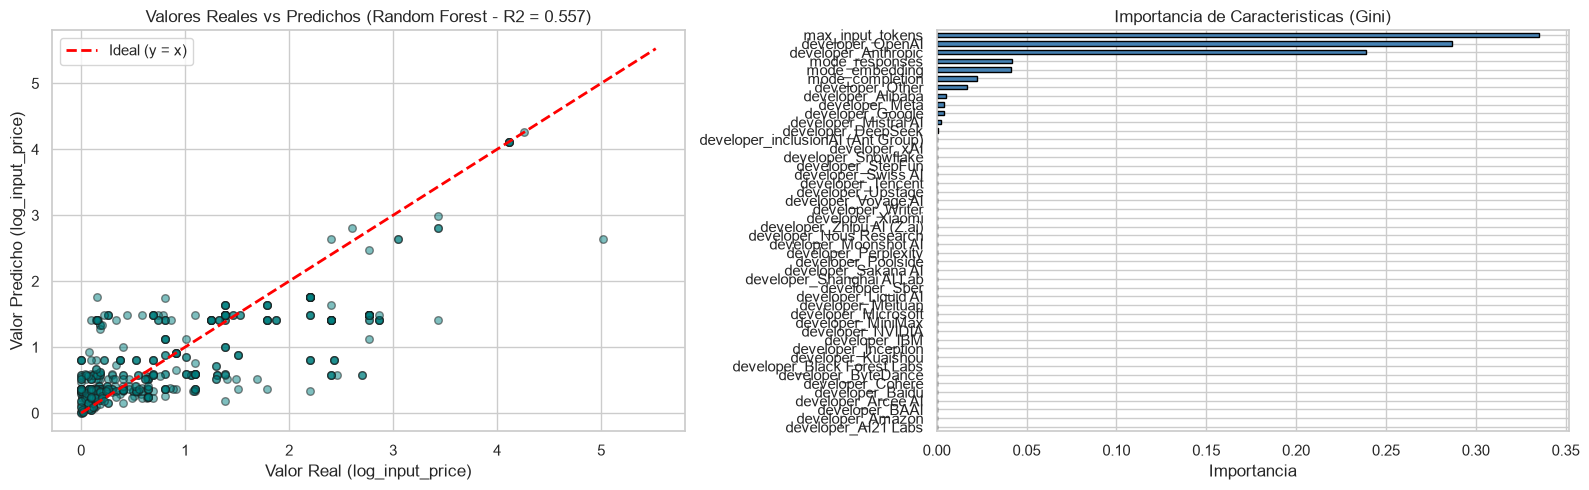

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

indices = np.random.RandomState(42).choice(len(y_test), size=min(500, len(y_test)), replace=False)
ax[0].scatter(y_test.iloc[indices], pred_rf[indices], alpha=0.5, color="teal", edgecolor="k", s=30)
recta = np.linspace(y_test.min(), y_test.max(), 100)
ax[0].plot(recta, recta, color="red", linestyle="--", linewidth=2, label="Ideal (y = x)")
ax[0].set_title(f"Valores Reales vs Predichos (Random Forest - R2 = {r2_rf:.3f})")
ax[0].set_xlabel("Valor Real (log_input_price)")
ax[0].set_ylabel("Valor Predicho (log_input_price)")
ax[0].legend()

importancias = pd.Series(rf.feature_importances_, index=x.columns).sort_values(ascending=True)
importancias.plot(kind="barh", ax=ax[1], color="steelblue", edgecolor="black")
ax[1].set_title("Importancia de Caracteristicas (Gini)")
ax[1].set_xlabel("Importancia")
plt.tight_layout()
plt.show()


> **Resumen del bloque:** Se grafican los valores reales vs predichos y la importancia de caracteristicas, confirmando que la modalidad y el desarrollador definen el precio por encima de la ventana de contexto.


In [30]:
y_real = np.expm1(y_test)
evaluacion = pd.DataFrame({
    "Modelo": ["Linea base (Promedio)", "Regresion Lineal (Ridge)", "Random Forest Regressor"],
    "R2": [f"{r2_base:.4f}", f"{r2_lineal:.4f}", f"{r2_rf:.4f}"],
    "MAE (Escala Log)": [f"{mae_base:.4f}", f"{mae_lineal:.4f}", f"{mae_rf:.4f}"],
    "RMSE (Escala Log)": ["-", f"{rmse_lineal:.4f}", f"{rmse_rf:.4f}"],
    "MAE Real ($/1M tokens)": [
        f"${mean_absolute_error(y_real, np.expm1(prediccion_base)):.4f}",
        f"${mean_absolute_error(y_real, np.expm1(pred_lineal)):.4f}",
        f"${mean_absolute_error(y_real, np.expm1(pred_rf)):.4f}"
    ]
})
display(evaluacion)


,Modelo,R2,MAE (Escala Log),RMSE (Escala Log),MAE Real ($/1M tokens)
0,Linea base (Promedio),-0.0001,0.6580,-,$2.7809
1,Regresion Lineal (Ridge),0.3284,0.4920,0.7020,$2.4380
2,Random Forest Regressor,0.5570,0.3949,0.5702,$1.8184


> **Resumen del bloque:** Se consolida la tabla comparativa final de desempeno: Random Forest reduce el error en un 39% frente a la linea base y explica el 55,7% de la varianza.


## 6. Conclusiones y Respuestas
Sintesis de las respuestas a las 5 preguntas del proyecto basadas en evidencia cuantitativa:

### Pregunta 1: Deflacion historica (2023-2026)
- **Hallazgo:** Tendencia deflacionaria pronunciada en los precios de inferencia de los principales creadores.
- **Cifra:** El costo de entrada en OpenAI cayo de $30,00 USD (GPT-4) a $0,15 USD (GPT-4o-mini), una reduccion del 99,5%, con caida interanual media del 76,8%.
- **Implicacion:** La inferencia es un *commodity*; se recomienda no firmar acuerdos de precio fijo de largo plazo.

### Pregunta 2: Disparidad entre nubes para Llama 3
- **Hallazgo:** Alojar el mismo modelo abierto presenta variaciones de precio marcadas segun la plataforma.
- **Cifra:** DeepInfra promedia $0,52 USD/1M tokens frente a $3,60 USD en Azure AI (razon de dispersion de 6,92x o sobrecosto >500%).
- **Implicacion:** Implementar un router de inferencia dinamico genera ahorros de mas del 80% en costos de nube.

### Pregunta 3: Ventana de contexto vs precio
- **Hallazgo:** La amplitud de la ventana de contexto no incrementa el costo unitario por token.
- **Cifra:** Correlacion de Pearson casi nula ($r = -0,019$); modelos con 1M de tokens cotizan desde $0,075 USD/1M tokens.
- **Implicacion:** Se pueden procesar documentos extensos sin recargo por token; la variable critica es la latencia de respuesta.

### Pregunta 4: Estructura por modalidad y salida vs entrada
- **Hallazgo:** Generar tokens de salida cuesta mas que leer tokens de entrada, y los embeddings son los mas economicos.
- **Cifra:** El token de salida cuesta en promedio 3,45 veces mas que el de entrada; mediana de entrada en $0,50 USD vs salida en $1,80 USD (embeddings: $0,02 USD).
- **Implicacion:** La optimizacion de prompts debe enfocarse en limitar el tamano de respuesta para maximizar el ahorro.

### Pregunta 5: Costos por consulta y atipicos
- **Hallazgo:** Modelos ligeros dominan en costo-eficiencia, mientras modelos insignia anteriores quedan como atipicos costosos.
- **Cifra:** Consulta tipica (1k in / 500 out) a $0,00045 USD en modelos ligeros vs $0,045 USD en modelos frontera antiguos; atipicos de Tukey representan el 7,82%.
- **Implicacion:** Rutear el 90% de solicitudes cotidianas a modelos destilados y reservar modelos frontera solo para razonamiento complejo.
